# IBM HR Analytics

In [336]:
import hvplot

In [337]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import hvplot.pandas
from sklearn.model_selection import train_test_split


In [338]:
hr = pd.read_csv(r'D:\Msc Data Science and AI\2ND YEAR\1st sem\Assessment 1\Datasets\IBM HR Analytics\WA_Fn-UseC_-HR-Employee-Attrition.csv')
hr.head(10)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


In [339]:
print(hr.shape)

(1470, 35)


## Exploratory Data Analysis

In [340]:
hr.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [341]:
#sumaary statistic

hr.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


###  1.1 Data Visualization

In [342]:
numerical_features = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
                 'PercentSalaryHike','TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 
                 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
categorical_features = ['Attrition', 'BusinessTravel','Department', 'Education', 'EducationField',
                    'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
                    'MaritalStatus', 'OverTime', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel',
                    'WorkLifeBalance','EmployeeCount', 'EmployeeNumber', 'Over18']

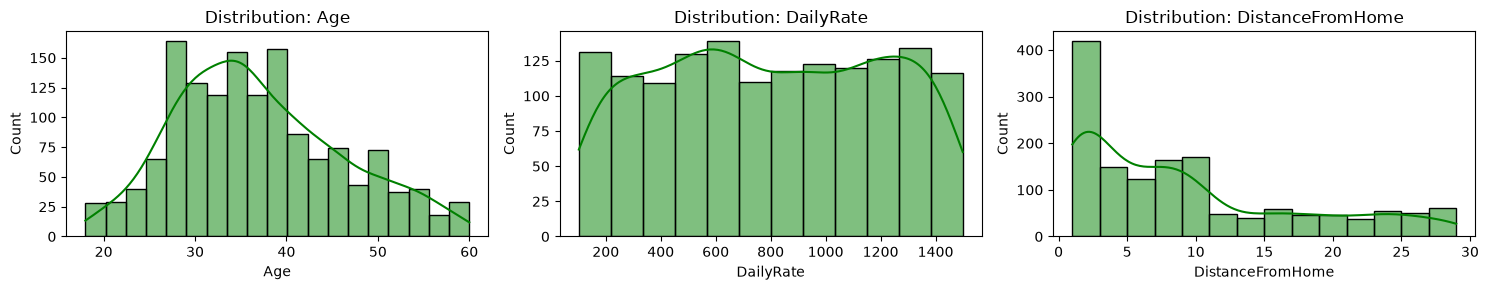

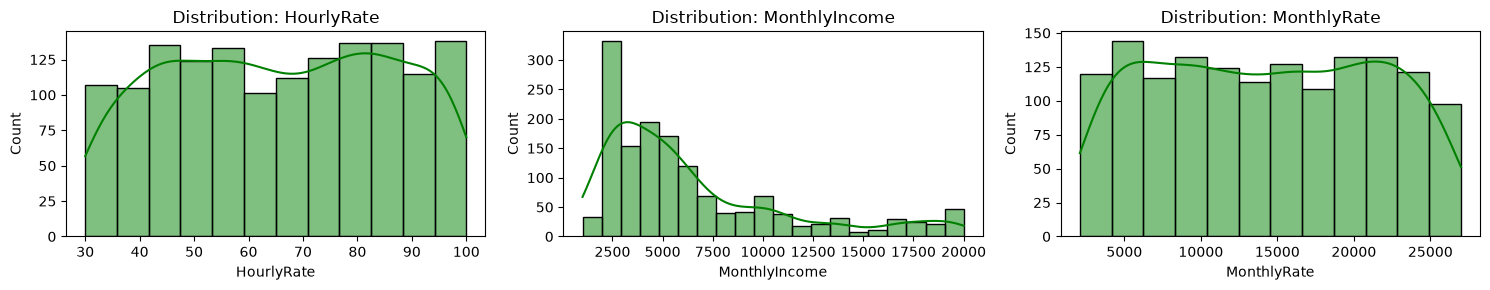

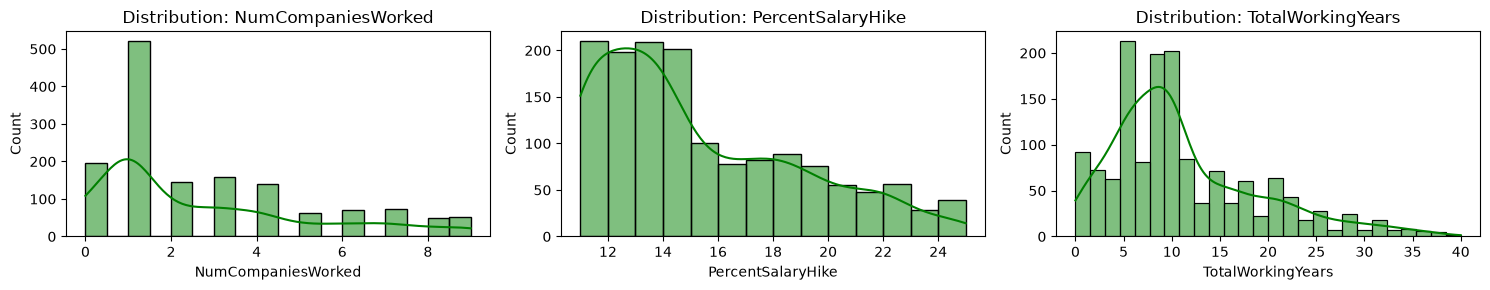

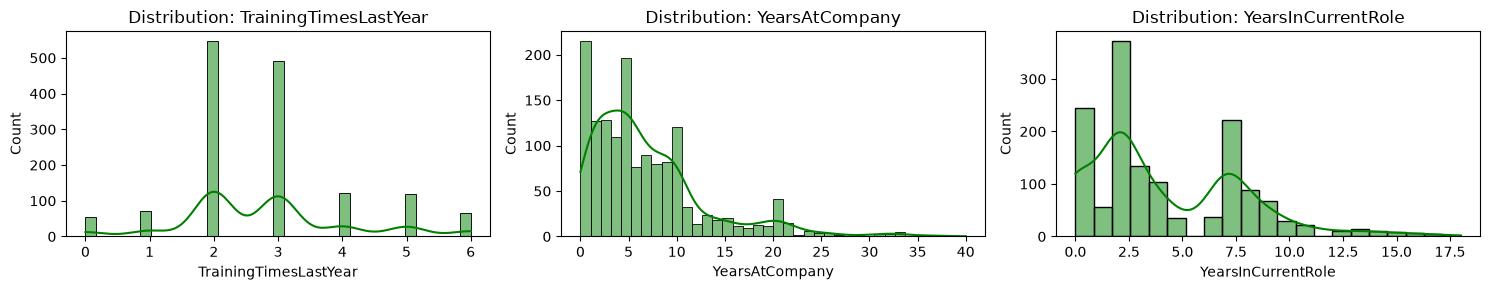

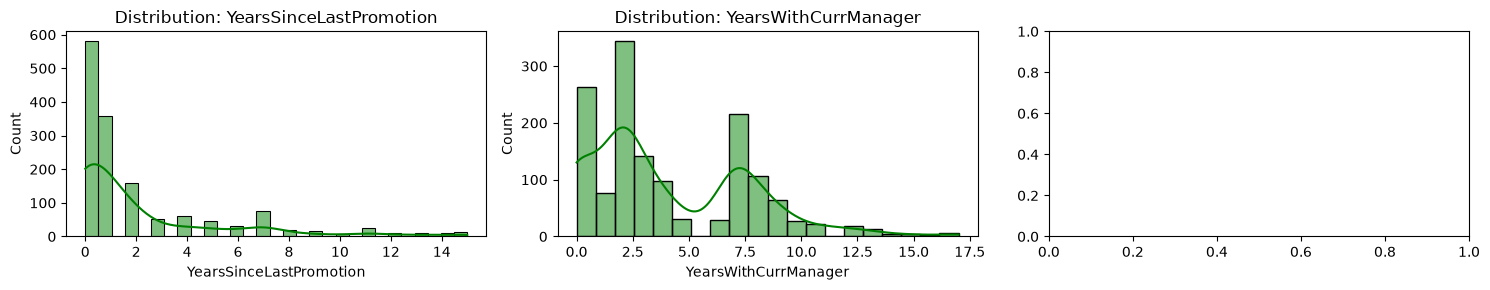

In [343]:
#identify distribution of each numerical features

for i in range(5):
    fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 3))

    for a, j in enumerate(numerical_features[i*3:(i*3)+3]):
        sns.histplot(
            data=hr,
            x=j,
            kde=True,
            color='green',
            ax=ax[a])
        ax[a].set_title('Distribution: ' + j)

    plt.tight_layout()
    plt.show()

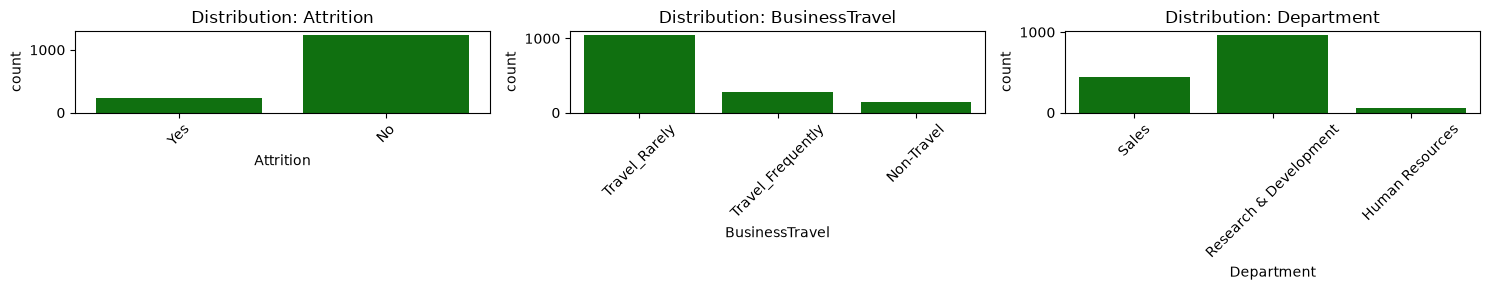

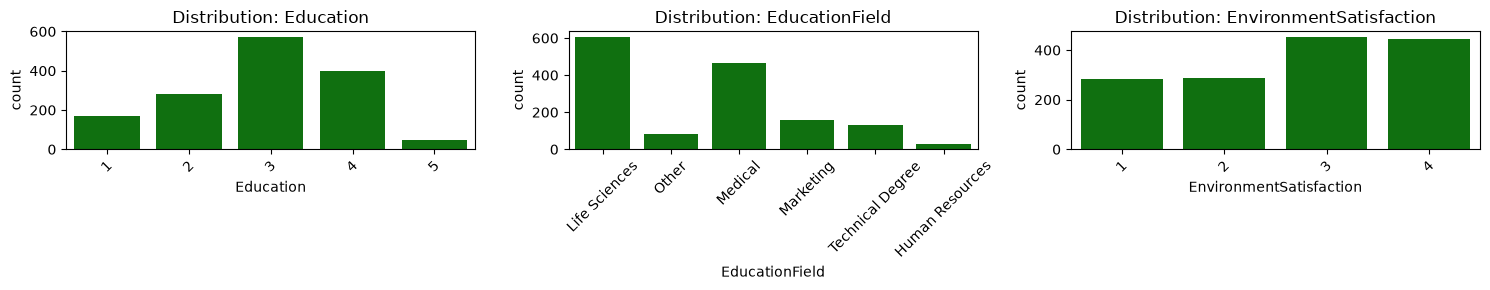

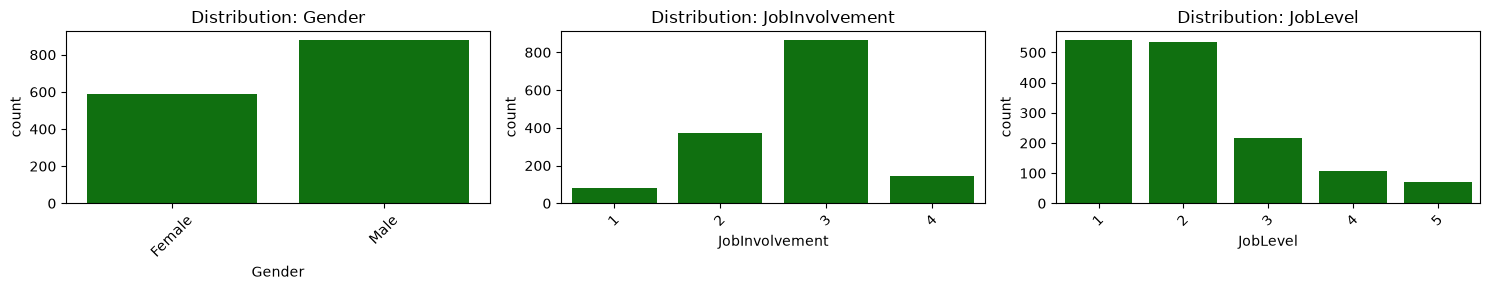

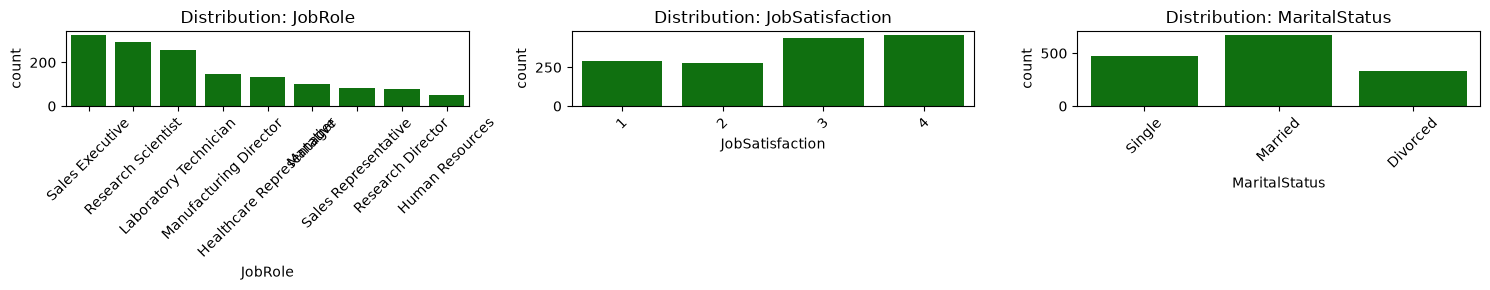

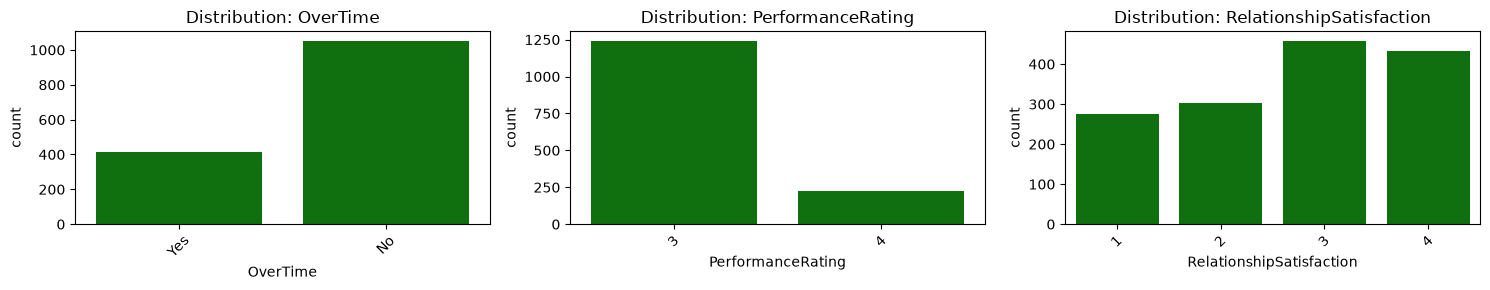

In [344]:
#distribution of categorical features

for i in range(5):
    fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 3))

    for a, j in enumerate(categorical_features[i*3:(i*3)+3]):
        sns.countplot(data=hr, x=j, color='green', ax=ax[a])

        ax[a].set_title('Distribution: ' + j)
        ax[a].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

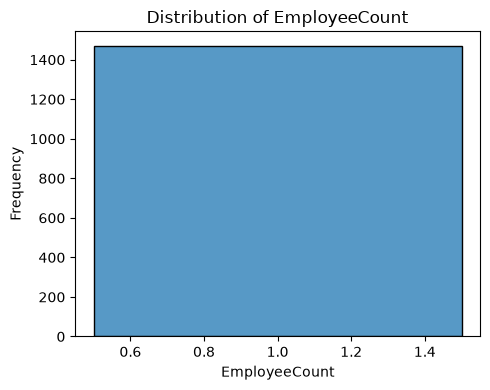

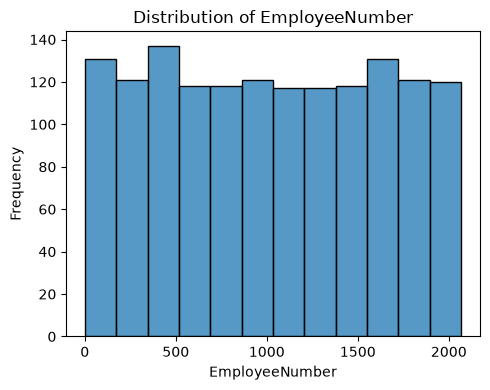

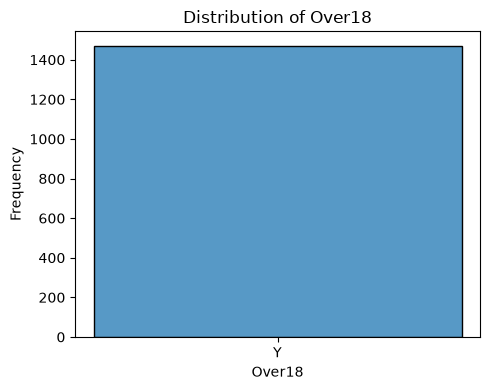

In [345]:
columns = ['EmployeeCount', 'EmployeeNumber', 'Over18']

for col in columns:
    plt.figure(figsize=(5, 4))

    sns.histplot(data=hr, x=col, kde=False)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

### 1.2 Target Variable - Attrition

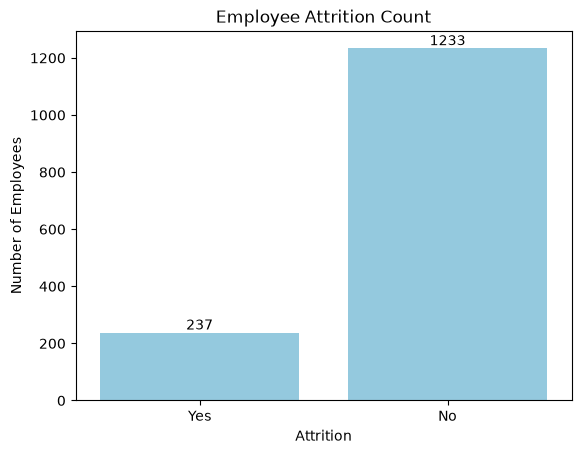

In [346]:

ax = sns.countplot(data=hr, x='Attrition', color='skyblue')
for container in ax.containers:
    ax.bar_label(container)

plt.title('Employee Attrition Count')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')

plt.show()

### 1.3 How each features affect to attrition

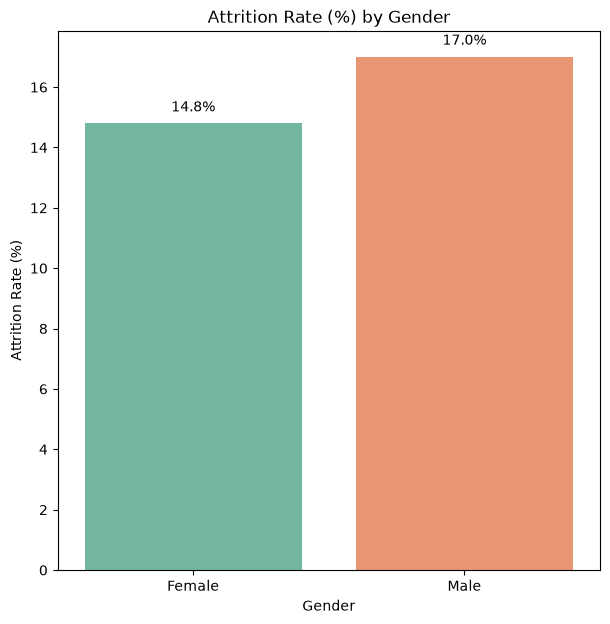

In [347]:
gender_attr = hr.groupby('Gender')['Attrition'].value_counts(normalize=True).unstack()['Yes'] * 100

plt.figure(figsize=(7, 7))
sns.barplot(x=gender_attr.index, y=gender_attr.values, hue=gender_attr.index, palette='Set2', legend=False)
plt.title('Attrition Rate (%) by Gender')
plt.ylabel('Attrition Rate (%)')
plt.xlabel('Gender')
for i, v in enumerate(gender_attr.values):
    plt.text(i, v + 0.4, f"{v:.1f}%", ha='center')
plt.show()

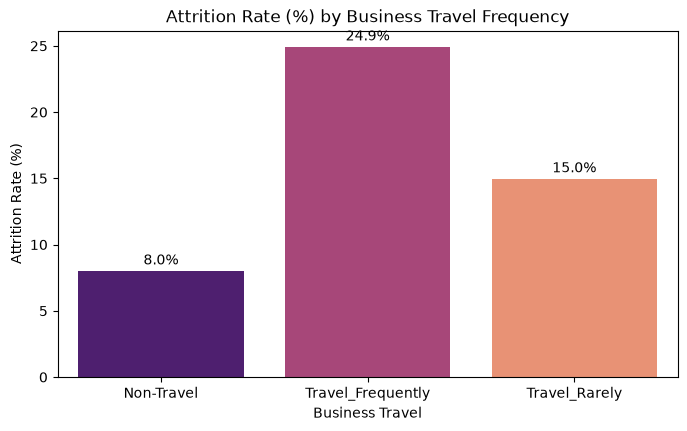

In [348]:
travel_attr = hr.groupby('BusinessTravel')['Attrition'].value_counts(normalize=True).unstack()['Yes'] * 100

plt.figure(figsize=(8, 4.5))
sns.barplot(x=travel_attr.index, y=travel_attr.values, hue=travel_attr.index, palette='magma', legend=False)
plt.title('Attrition Rate (%) by Business Travel Frequency')
plt.ylabel('Attrition Rate (%)')
plt.xlabel('Business Travel')
for i, v in enumerate(travel_attr.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center')
plt.show()

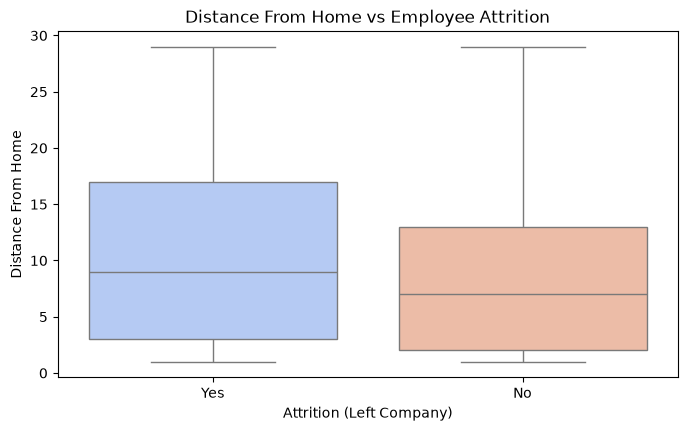

Attrition
No      8.915653
Yes    10.632911
Name: DistanceFromHome, dtype: float64


In [349]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(x='Attrition', y='DistanceFromHome', data=hr, hue='Attrition', palette='coolwarm', legend=False)
plt.title('Distance From Home vs Employee Attrition')
plt.xlabel('Attrition (Left Company)')
plt.ylabel('Distance From Home')
plt.show()

print(hr.groupby('Attrition')['DistanceFromHome'].mean())

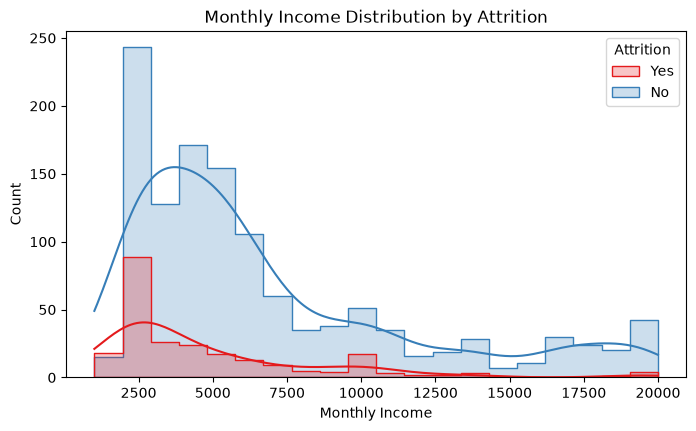

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


In [350]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=hr, x='MonthlyIncome', hue='Attrition', kde=True, palette='Set1', element="step")
plt.title('Monthly Income Distribution by Attrition')
plt.xlabel('Monthly Income')
plt.ylabel('Count')
plt.show()

print(hr.groupby('Attrition')['MonthlyIncome'].mean())

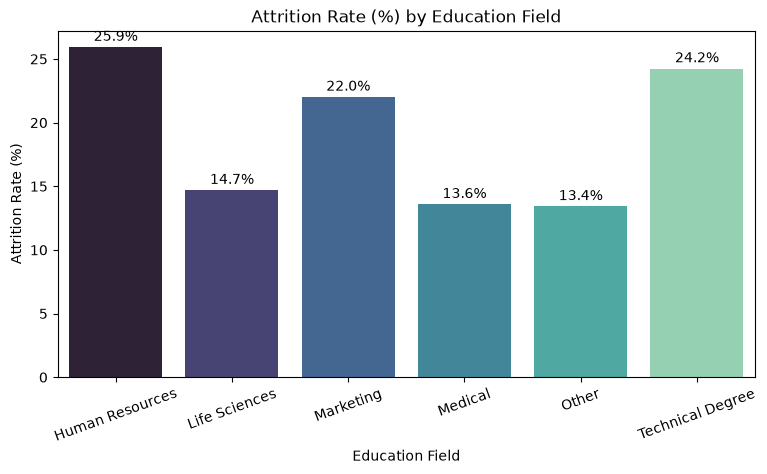

In [351]:
edu_attr = hr.groupby('EducationField')['Attrition'].value_counts(normalize=True).unstack()['Yes'] * 100

plt.figure(figsize=(9, 4.5))
sns.barplot(x=edu_attr.index, y=edu_attr.values, hue=edu_attr.index, palette='mako', legend=False)
plt.title('Attrition Rate (%) by Education Field')
plt.ylabel('Attrition Rate (%)')
plt.xlabel('Education Field')
plt.xticks(rotation=20)
for i, v in enumerate(edu_attr.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center')
plt.show()

               Department  Total  Left       Rate
0         Human Resources     63    12  19.047619
1  Research & Development    961   133  13.839750
2                   Sales    446    92  20.627803


Text(0.5, 1.0, 'Department Attrition')

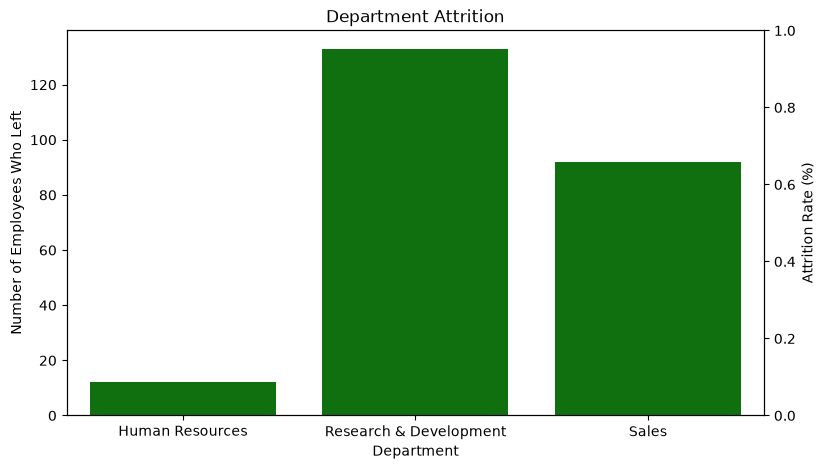

In [352]:
dept_summary = hr.groupby('Department')['Attrition'].agg(
    Total='count',
    Left=lambda x: (x == 'Yes').sum(),
    Rate=lambda x: (x == 'Yes').mean() * 100
).reset_index()

print(dept_summary)

fig, ax1 = plt.subplots(figsize=(9, 5))
sns.barplot(data=dept_summary, x='Department', y='Left', ax=ax1, color='green')
ax2 = ax1.twinx()

ax1.set_ylabel('Number of Employees Who Left')
ax2.set_ylabel('Attrition Rate (%)')
ax1.set_xlabel('Department')
plt.title('Department Attrition')


## 2. KPI - Attrition Rate by Department,Job Role,Overtime 

In [353]:
print(hr["Attrition"].value_counts())

Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [354]:
hr['Attrition'] = hr['Attrition'].map({'Yes': 1, 'No': 0})

In [355]:
attrition_summary = (
    hr.groupby(["Department", "JobRole", "OverTime"])
    .agg(
        Total_Employees=("Attrition", "size"),
        Employees_Left=("Attrition", "sum")
    )
    .reset_index()
)

attrition_summary["Attrition_Rate_Percent"] = (
    attrition_summary["Employees_Left"]
    / attrition_summary["Total_Employees"] * 100
)

display(
    attrition_summary
    .sort_values("Attrition_Rate_Percent", ascending=False)
    .round(2)
)

,Department,JobRole,OverTime,Total_Employees,Employees_Left,Attrition_Rate_Percent
21,Sales,Sales Representative,Yes,24,16,66.67
7,Research & Development,Laboratory Technician,Yes,62,31,50.00
1,Human Resources,Human Resources,Yes,13,5,38.46
15,Research & Development,Research Scientist,Yes,97,33,34.02
19,Sales,Sales Executive,Yes,94,31,32.98
20,Sales,Sales Representative,No,59,17,28.81
9,Research & Development,Manager,Yes,13,3,23.08
0,Human Resources,Human Resources,No,39,7,17.95
6,Research & Development,Laboratory Technician,No,197,31,15.74
18,Sales,Sales Executive,No,232,26,11.21


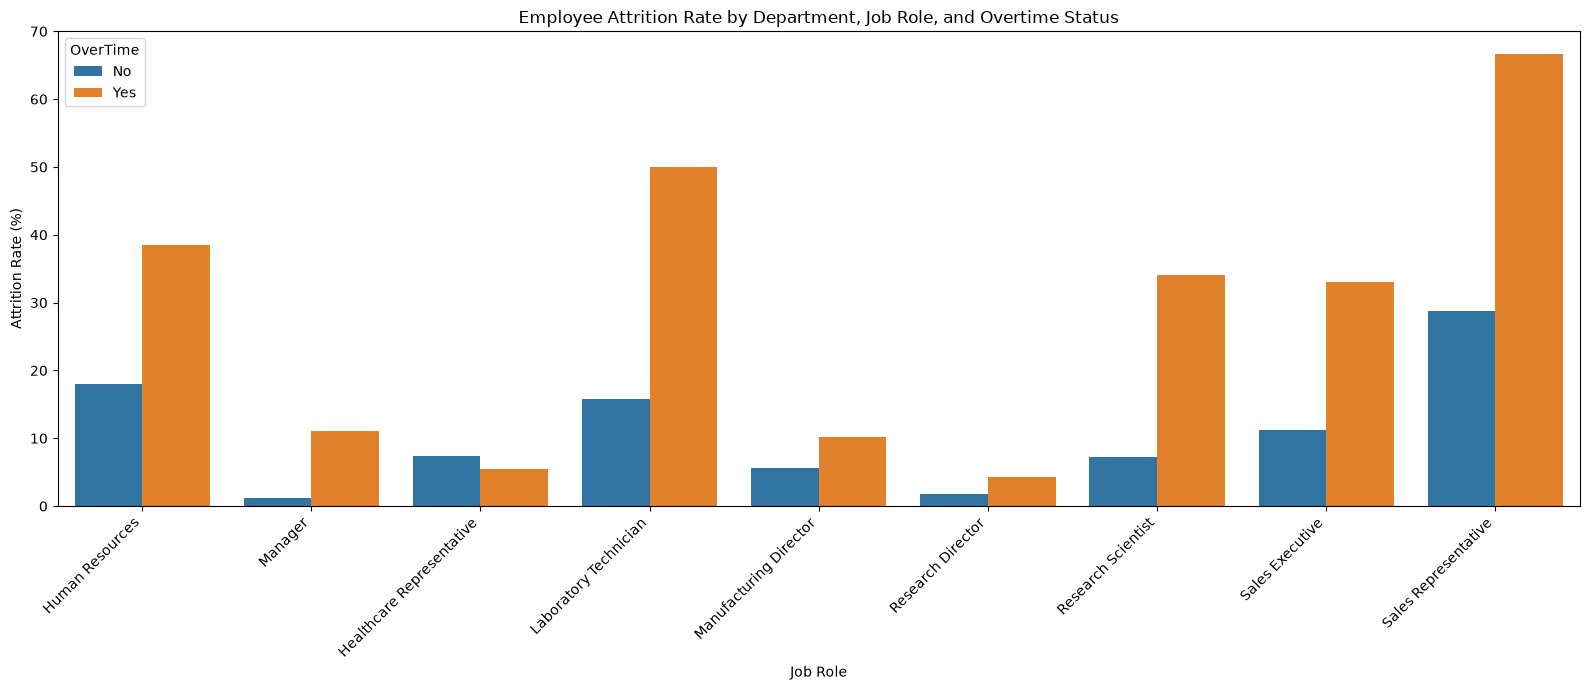

In [356]:
plt.figure(figsize=(16, 7))

sns.barplot(
    data=attrition_summary,
    x="JobRole",
    y="Attrition_Rate_Percent",
    hue="OverTime",
    errorbar=None
)

plt.title("Employee Attrition Rate by Department, Job Role, and Overtime Status")
plt.xlabel("Job Role")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="OverTime")
plt.tight_layout()
plt.show()

# 3. Data preprocessing

In [357]:
#check missing values and duplicates 

print(f'Total Missing Values: {hr.isnull().sum().sum()}')
print(f'Total Duplicated Rows: {hr.duplicated().sum()}')

Total Missing Values: 0
Total Duplicated Rows: 0


In [358]:
#outliers checking

numeric_cols = ['DailyRate','MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears',
                'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager',
                'NumCompaniesWorked', 'PercentSalaryHike']

print(f"{'Column':<22}{'Outliers':>10}{'% of data':>12}")
for col in numeric_cols:
    q1, q3 = hr[col].quantile(0.25), hr[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    outliers = hr[(hr[col] < lower) | (hr[col] > upper)]
    print(f"{col:<22}{len(outliers):>10}{len(outliers)/len(hr)*100:>11.2f}%")

Column                  Outliers   % of data
DailyRate                      0       0.00%
MonthlyIncome                114       7.76%
DistanceFromHome               0       0.00%
TotalWorkingYears             63       4.29%
YearsAtCompany               104       7.07%
YearsInCurrentRole            21       1.43%
YearsWithCurrManager          14       0.95%
NumCompaniesWorked            52       3.54%
PercentSalaryHike              0       0.00%


In [359]:
#identifyimg Unique features

print(hr['EmployeeCount'].nunique())
print(hr['Over18'].nunique())
print(hr['EmployeeNumber'].nunique())
print(hr['StandardHours'].nunique())

1
1
1470
1


In [360]:
#removing features have unique values and identifier
hr.drop(['EmployeeCount','EmployeeNumber', 'Over18','StandardHours'], axis="columns", inplace=True)

## 3.1 Feature Engineering & Encoding

### 1) Binary Encoding

In [361]:
hr['OverTime'] = hr['OverTime'].map({'Yes': 1, 'No': 0})
hr['Gender'] = hr['Gender'].map({'Male': 1, 'Female': 0})

### 2) create new feature - Tenure_group

In [362]:
hr['TenureGroup'] = pd.cut( hr['YearsAtCompany'],bins=[-1, 1, 5, 10, np.inf], labels=['0–1 years', '2–5 years', '6–10 years', 'Over 10 years'])

### 3) Ordinal Encoding -Tenure group

In [363]:
hr['TenureGroup'].unique()

['6–10 years', '0–1 years', '2–5 years', 'Over 10 years']
Categories (4, str): ['0–1 years' < '2–5 years' < '6–10 years' < 'Over 10 years']

In [364]:
hr['TenureGroup'] = hr['TenureGroup'].cat.rename_categories({
    '0–1 years': 'New Employee',
    '2–5 years': 'Early Career',
    '6–10 years': 'Mid Tenure',
    'Over 10 years': 'Long Tenure'
})

In [365]:
tenure_mapping = {
    'New Employee': 0,
    'Early Career': 1,
    'Mid Tenure': 2,
    'Long Tenure': 3}

hr['TenureGroup'] = hr['TenureGroup'].astype(str).map(tenure_mapping).astype(int)

In [366]:
hr['TenureGroup'].unique()

array([2, 0, 1, 3])

### 4) create new feature- overallSatisfaction

In [367]:
satisfaction_cols = [
    'EnvironmentSatisfaction',
    'JobSatisfaction',
    'RelationshipSatisfaction',
    'WorkLifeBalance']

hr['OverallSatisfaction'] = hr[satisfaction_cols].mean(axis=1)

### 5) One-hot Encoding


In [368]:
categorical_cols = [
    'BusinessTravel',
    'Department',
    'EducationField',
    'JobRole',
    'MaritalStatus']

hr = pd.get_dummies(hr,columns=categorical_cols,dtype=int)

In [369]:
hr.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 52 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                1470 non-null   int64  
 1   Attrition                          1470 non-null   int64  
 2   DailyRate                          1470 non-null   int64  
 3   DistanceFromHome                   1470 non-null   int64  
 4   Education                          1470 non-null   int64  
 5   EnvironmentSatisfaction            1470 non-null   int64  
 6   Gender                             1470 non-null   int64  
 7   HourlyRate                         1470 non-null   int64  
 8   JobInvolvement                     1470 non-null   int64  
 9   JobLevel                           1470 non-null   int64  
 10  JobSatisfaction                    1470 non-null   int64  
 11  MonthlyIncome                      1470 non-null   int64  
 12  Mon

In [370]:
hr.drop(columns=['YearsAtCompany','EnvironmentSatisfaction','JobSatisfaction', 'RelationshipSatisfaction','WorkLifeBalance'],inplace=True)

In [371]:
print(hr.columns.intersection([
    'YearsAtCompany',
    'EnvironmentSatisfaction',
    'JobSatisfaction',
    'RelationshipSatisfaction',
    'WorkLifeBalance'
]))

Index([], dtype='str')


# 4. Split into test and traing using stratified sampling

In [372]:
X = hr.drop(['Attrition'], axis=1, errors='ignore')
Y = hr['Attrition']

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42, stratify=Y)

In [373]:
print(hr.shape)
print(X.shape, Y.shape)

(1470, 47)
(1470, 46) (1470,)


In [374]:
print("Training set:")
print(Y_train.value_counts(normalize=True))

print("\nTesting set:")
print(Y_test.value_counts(normalize=True))

Training set:
Attrition
0    0.838678
1    0.161322
Name: proportion, dtype: float64

Testing set:
Attrition
0    0.839002
1    0.160998
Name: proportion, dtype: float64


# 5. Data Balancing - Synthetic Minority Oversampling Technique (SMOTE)

In [375]:
print(hr["Attrition"].value_counts())

Attrition
0    1233
1     237
Name: count, dtype: int64


In [376]:
import imblearn
from collections import Counter
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

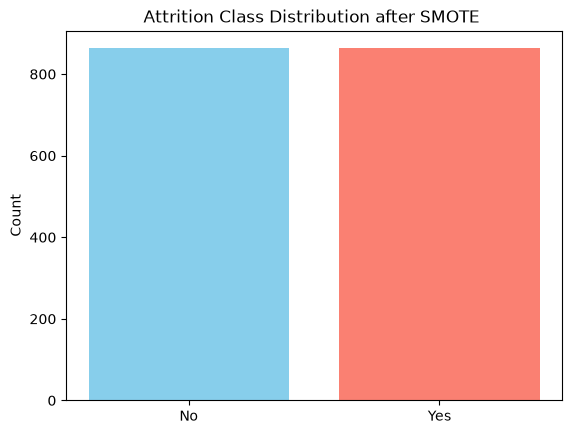

Before SMOTE: Counter({0: 863, 1: 166})
After SMOTE: Counter({0: 863, 1: 863})
Test set: Counter({0: 370, 1: 71})


In [377]:
smote = SMOTE(sampling_strategy='minority', random_state=42)
X_train_sm, Y_train_sm = smote.fit_resample(X_train, Y_train)

plt.bar(Y_train_sm.value_counts().index, Y_train_sm.value_counts().values, 
        color=['skyblue','salmon'])
plt.xticks([0,1], ['No', 'Yes'])
plt.ylabel("Count")
plt.title("Attrition Class Distribution after SMOTE ")
plt.show()

print("Before SMOTE:", Counter(Y_train))
print("After SMOTE:", Counter(Y_train_sm))
print("Test set:", Counter(Y_test))



# 6. Data Scaling

In [378]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler

In [379]:

num_cols = X_train_sm.select_dtypes(include=['int64', 'float64']).columns
skewness = X_train_sm[num_cols].skew().sort_values(ascending=False)

print(skewness)

EducationField_Human Resources       9.646821
JobRole_Human Resources              6.520541
Department_Human Resources           5.953480
EducationField_Other                 5.684176
JobRole_Research Director            5.389410
JobRole_Sales Representative         4.700482
JobRole_Manager                      4.448705
JobRole_Healthcare Representative    3.905531
JobRole_Manufacturing Director       3.765089
BusinessTravel_Non-Travel            3.516516
EducationField_Technical Degree      3.478665
EducationField_Marketing             3.237102
PerformanceRating                    2.697191
JobRole_Research Scientist           2.174994
YearsSinceLastPromotion              2.140435
BusinessTravel_Travel_Frequently     2.095260
MaritalStatus_Divorced               1.993674
JobRole_Laboratory Technician        1.948790
JobRole_Sales Executive              1.557707
MonthlyIncome                        1.521702
EducationField_Medical               1.355969
StockOptionLevel                  

In [380]:
# Select one-hot-encoded columns
one_hot_cols = [
    col for col in hr.columns
    if any(col.startswith(prefix) for prefix in [
        'BusinessTravel_', 'Department_','EducationField_', 'JobRole_', 'MaritalStatus_'])]

for col in one_hot_cols:
    print(f"\n{col}")
    print(hr[col].value_counts().sort_index())



BusinessTravel_Non-Travel
BusinessTravel_Non-Travel
0    1320
1     150
Name: count, dtype: int64

BusinessTravel_Travel_Frequently
BusinessTravel_Travel_Frequently
0    1193
1     277
Name: count, dtype: int64

BusinessTravel_Travel_Rarely
BusinessTravel_Travel_Rarely
0     427
1    1043
Name: count, dtype: int64

Department_Human Resources
Department_Human Resources
0    1407
1      63
Name: count, dtype: int64

Department_Research & Development
Department_Research & Development
0    509
1    961
Name: count, dtype: int64

Department_Sales
Department_Sales
0    1024
1     446
Name: count, dtype: int64

EducationField_Human Resources
EducationField_Human Resources
0    1443
1      27
Name: count, dtype: int64

EducationField_Life Sciences
EducationField_Life Sciences
0    864
1    606
Name: count, dtype: int64

EducationField_Marketing
EducationField_Marketing
0    1311
1     159
Name: count, dtype: int64

EducationField_Medical
EducationField_Medical
0    1006
1     464
Name: count,

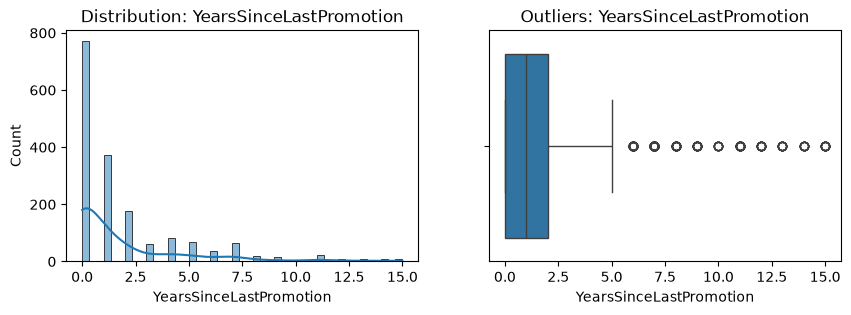

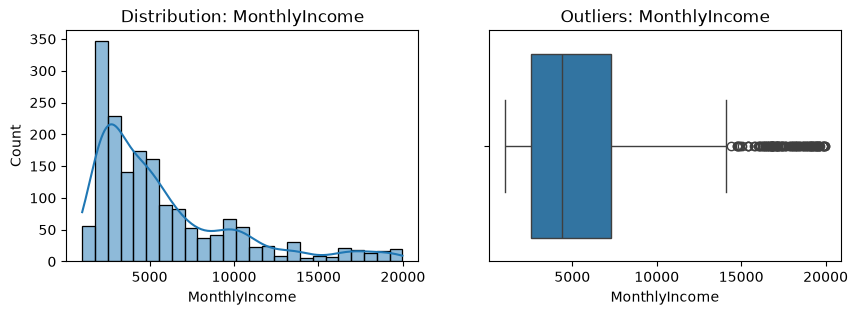

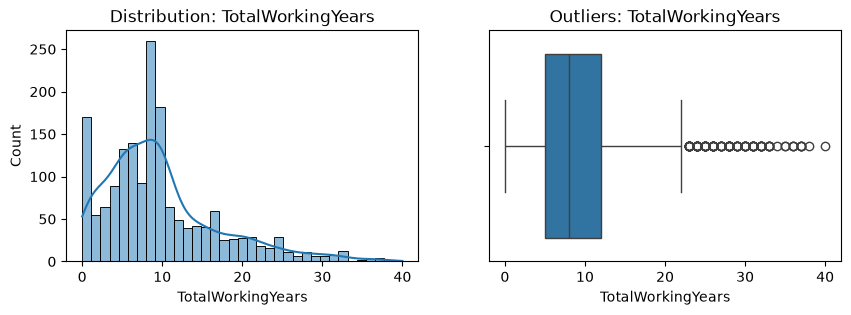

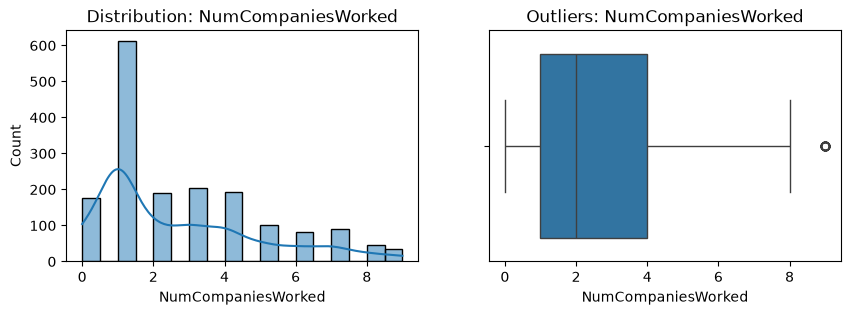

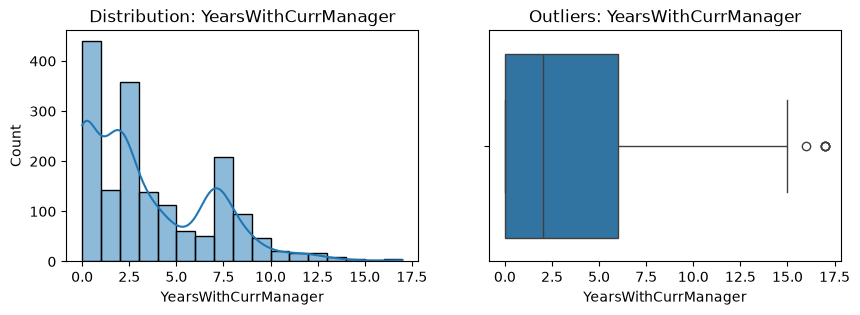

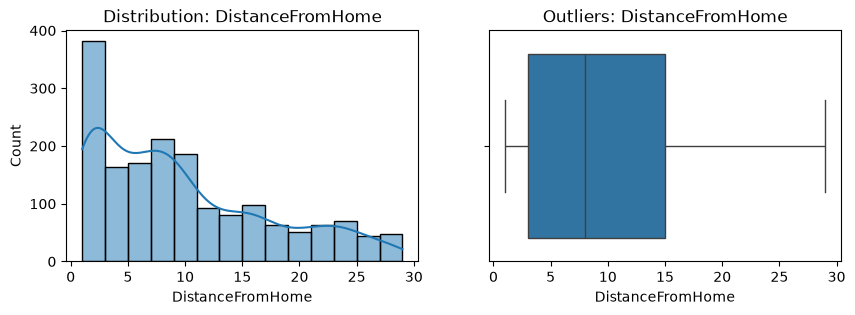

In [381]:
cols_to_check = [
    'YearsSinceLastPromotion',
        'MonthlyIncome',
    'TotalWorkingYears',
    'NumCompaniesWorked',
    'YearsWithCurrManager','DistanceFromHome'
]

for col in cols_to_check:
    if col in X_train_sm.columns:
        fig, axes = plt.subplots(1, 2, figsize=(10, 3))

        sns.histplot(X_train_sm[col], kde=True, ax=axes[0])
        axes[0].set_title(f'Distribution: {col}')

        sns.boxplot(x=X_train_sm[col], ax=axes[1])
        axes[1].set_title(f'Outliers: {col}')

 ## Apply Log transformation for reduce skewness

In [382]:
X_train_sm['MonthlyIncome'] = np.log1p(X_train_sm['MonthlyIncome'])
X_train_sm['TotalWorkingYears'] = np.log1p(X_train_sm['TotalWorkingYears'])
X_train_sm['YearsSinceLastPromotion'] = np.log1p(X_train_sm['YearsSinceLastPromotion'])
X_train_sm['NumCompaniesWorked'] = np.log1p(X_train_sm['NumCompaniesWorked'])
X_train_sm['YearsWithCurrManager'] = np.log1p(X_train_sm['YearsWithCurrManager'])


X_test['MonthlyIncome'] = np.log1p(X_test['MonthlyIncome'])
X_test['TotalWorkingYears'] = np.log1p(X_test['TotalWorkingYears'])
X_test['YearsSinceLastPromotion'] = np.log1p(X_test['YearsSinceLastPromotion'])
X_test['NumCompaniesWorked'] = np.log1p(X_test['NumCompaniesWorked'])
X_test['YearsWithCurrManager'] = np.log1p(X_test['YearsWithCurrManager'])


In [383]:
num_cols = X_train_sm.select_dtypes(include=['int64', 'float64']).columns
skewness = X_train_sm[num_cols].skew().sort_values(ascending=False)

print(skewness)

EducationField_Human Resources       9.646821
JobRole_Human Resources              6.520541
Department_Human Resources           5.953480
EducationField_Other                 5.684176
JobRole_Research Director            5.389410
JobRole_Sales Representative         4.700482
JobRole_Manager                      4.448705
JobRole_Healthcare Representative    3.905531
JobRole_Manufacturing Director       3.765089
BusinessTravel_Non-Travel            3.516516
EducationField_Technical Degree      3.478665
EducationField_Marketing             3.237102
PerformanceRating                    2.697191
JobRole_Research Scientist           2.174994
BusinessTravel_Travel_Frequently     2.095260
MaritalStatus_Divorced               1.993674
JobRole_Laboratory Technician        1.948790
JobRole_Sales Executive              1.557707
EducationField_Medical               1.355969
StockOptionLevel                     1.327355
JobLevel                             1.202698
Department_Sales                  

### Apply standardization 

In [384]:
# Standardization

from sklearn.preprocessing import StandardScaler

cols = ['MonthlyIncome', 'TotalWorkingYears', 'YearsInCurrentRole',
        'YearsWithCurrManager', 'NumCompaniesWorked', 'DistanceFromHome',
        'JobInvolvement', 'JobLevel', 'OverTime',
        'StockOptionLevel', 'HourlyRate','MonthlyRate','DailyRate','TrainingTimesLastYear','PercentSalaryHike']

ss = StandardScaler()
X_train_sm[cols] = ss.fit_transform(X_train_sm[cols])
X_test[cols] = ss.transform(X_test[cols])


# 7. Independance Testing 

### 7.1) Pearson Correlation - Numerical Features

In [385]:
from scipy.stats import pearsonr, spearmanr

In [386]:
numerical_cols = [
    'Age'
    'DailyRate',
    'DistanceFromHome',
    'Education',
    'HourlyRate',
    'JobInvolvement',
    'JobLevel',
    'MonthlyIncome',
    'MonthlyRate',
    'NumCompaniesWorked',
    'PercentSalaryHike',
    'PerformanceRating',
    'StockOptionLevel',
    'TotalWorkingYears',
    'TrainingTimesLastYear',
    'YearsInCurrentRole',
    'YearsSinceLastPromotion',
    'YearsWithCurrManager',
    'OverallSatisfaction'
]

In [387]:
results = []

for feature in numerical_cols:
    if feature in X_train_sm.columns:

        x = X_train_sm[feature]
        y = Y_train_sm

        valid = x.notna() & y.notna()

        if x[valid].nunique() > 1 and y[valid].nunique() > 1:
            r, p = pearsonr(x[valid], y[valid])

            results.append({
                'Feature': feature,
                'Pearson_Correlation': r,
                'P_Value': p,
                'Significant': p < 0.05
            })

correlation_results = pd.DataFrame(results)

correlation_results['Abs_Correlation'] = (
    correlation_results['Pearson_Correlation'].abs()
)

correlation_results = correlation_results.sort_values(
    'Abs_Correlation', ascending=False
)

display(correlation_results.round(4))

,Feature,Pearson_Correlation,P_Value,Significant,Abs_Correlation
10,StockOptionLevel,-0.3426,0.0000,True,0.3426
11,TotalWorkingYears,-0.3321,0.0000,True,0.3321
15,YearsWithCurrManager,-0.3240,0.0000,True,0.3240
4,JobLevel,-0.3209,0.0000,True,0.3209
3,JobInvolvement,-0.3194,0.0000,True,0.3194
13,YearsInCurrentRole,-0.3190,0.0000,True,0.3190
5,MonthlyIncome,-0.2964,0.0000,True,0.2964
16,OverallSatisfaction,-0.2537,0.0000,True,0.2537
1,Education,-0.2024,0.0000,True,0.2024
12,TrainingTimesLastYear,-0.1987,0.0000,True,0.1987


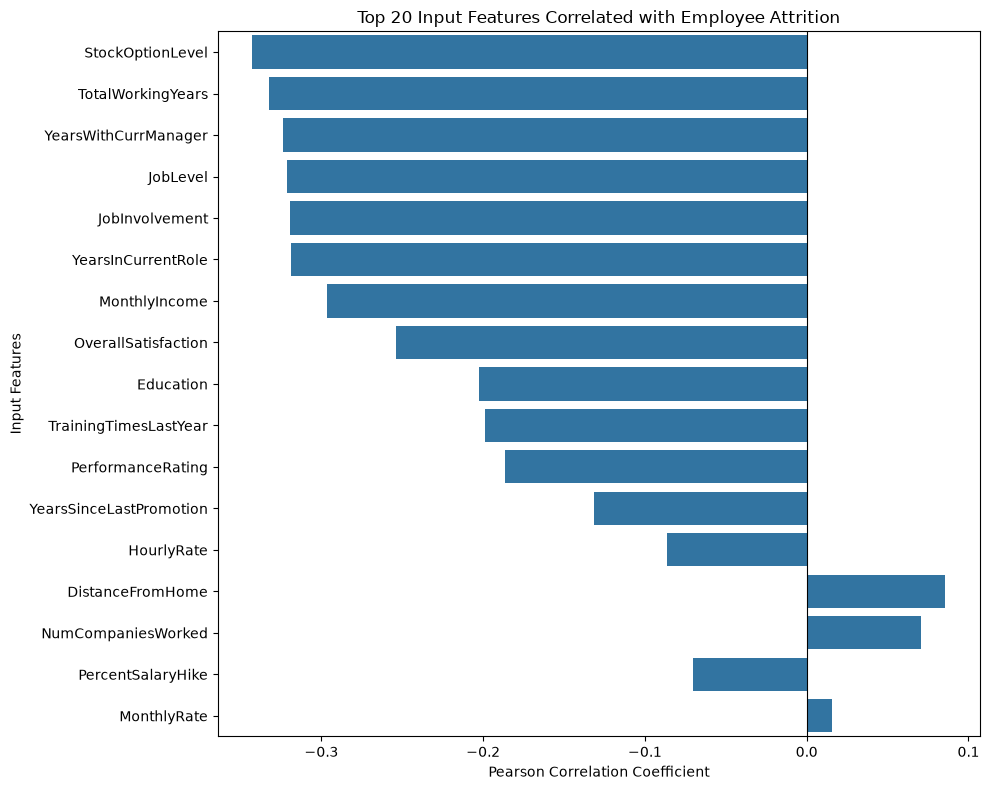

In [388]:
plt.figure(figsize=(10, 8)) 
plot_data = correlation_results.sort_values('Pearson_Correlation', ascending=True).copy()
sns.barplot(data=correlation_results.head(20),x='Pearson_Correlation', y='Feature')


plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 20 Input Features Correlated with Employee Attrition')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Input Features')
plt.tight_layout()
plt.show()

### 7.2) Chi-Square Test - Categorical Features

In [389]:
categorical_cols = [
   'Gender',
    'OverTime',
    'TenureGroup',
    'Department_Research & Development',
    'Department_Sales',
    'Department_Human Resources',
    'EducationField_Human Resources',
    'EducationField_Life Sciences',
    'EducationField_Medical',
    'EducationField_Marketing',
    'EducationField_Other',
    'EducationField_Technical Degree',
    'JobRole_Human Resources',
    'JobRole_Research Director',
    'JobRole_Sales Representative',
    'JobRole_Manager',
    'JobRole_Healthcare Representative',
    'JobRole_Manufacturing Director',
    'JobRole_Research Scientist',
    'JobRole_Laboratory Technician',
    'JobRole_Sales Executive',
    'BusinessTravel_Non-Travel',
    'BusinessTravel_Travel_Frequently',
    'BusinessTravel_Travel_Rarely',
    'MaritalStatus_Divorced',
    'MaritalStatus_Single',
    'MaritalStatus_Married'
]

In [390]:
from scipy.stats import chi2_contingency

results = []

for feature in categorical_cols:
    if feature in X_train_sm.columns:

        contingency_table = pd.crosstab(
            X_train_sm[feature],
            Y_train_sm
        )

        if contingency_table.shape[0] > 1 and contingency_table.shape[1] > 1:

            chi2, p, dof, expected = chi2_contingency(
                contingency_table
            )

            results.append({
                'Feature': feature,
                'Chi2_Statistic': chi2,
                'P_Value': p,
                'Degrees_of_Freedom': dof,
                'Significant': p < 0.05
            })

chi_square_results = pd.DataFrame(results)

chi_square_results = chi_square_results.sort_values(
    'P_Value', ascending=True
)

display(chi_square_results.round(4))

,Feature,Chi2_Statistic,P_Value,Degrees_of_Freedom,Significant
2,TenureGroup,308.4448,0.0000,3,True
26,MaritalStatus_Married,222.8776,0.0000,1,True
3,Department_Research & Development,161.7157,0.0000,1,True
7,EducationField_Life Sciences,127.7437,0.0000,1,True
24,MaritalStatus_Divorced,105.2575,0.0000,1,True
8,EducationField_Medical,97.7084,0.0000,1,True
17,JobRole_Manufacturing Director,81.4388,0.0000,1,True
23,BusinessTravel_Travel_Rarely,80.8505,0.0000,1,True
21,BusinessTravel_Non-Travel,80.1500,0.0000,1,True
16,JobRole_Healthcare Representative,78.5999,0.0000,1,True


# 8. Modeling

### 8.1 Feature selection = L1-Logidtic regression

In [391]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RepeatedStratifiedKFold
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

In [392]:
# Create L1 Logistic Regression model
lasso_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        penalty='l1',
        solver='liblinear',
        C=1.0,
        max_iter=2000,
        class_weight='balanced',
        random_state=1000
    ))
])

In [393]:
lasso_model.fit(X_train_sm, Y_train_sm)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    penalty='l1', random_state=1000,
                                    solver='liblinear'))])

In [394]:
y_pred_lasso = lasso_model.predict(X_test)

In [395]:
# Extract coefficients from the trained model
coefficients = lasso_model.named_steps['model'].coef_[0]

# Create a feature table
lasso_features = pd.DataFrame({
    'Feature': X_train_sm.columns,
    'Coefficient': coefficients
})

# Separate selected and removed features
selected_features = lasso_features[lasso_features['Coefficient'].abs() > 1e-8].copy()

removed_features = lasso_features[lasso_features['Coefficient'].abs() <= 1e-8].copy()

# Sort by coefficient magnitude
selected_features['Abs_Coefficient'] = (selected_features['Coefficient'].abs())

selected_features = selected_features.sort_values('Abs_Coefficient', ascending=False)

print("Selected features:")
display(selected_features)

print("removed_features:")
display(removed_features)

print("Number of selected features:", len(selected_features))
print("Number of removed features:", len(removed_features))

Selected features:


,Feature,Coefficient,Abs_Coefficient
44,MaritalStatus_Married,-1.956653,1.956653
29,EducationField_Life Sciences,-1.760897,1.760897
31,EducationField_Medical,-1.628092,1.628092
43,MaritalStatus_Divorced,-1.589668,1.589668
45,MaritalStatus_Single,-1.567857,1.567857
27,Department_Sales,-1.281348,1.281348
40,JobRole_Research Scientist,-1.273703,1.273703
24,BusinessTravel_Travel_Rarely,-1.055103,1.055103
34,JobRole_Healthcare Representative,-0.941141,0.941141
38,JobRole_Manufacturing Director,-0.934027,0.934027


removed_features:


,Feature,Coefficient
35,JobRole_Human Resources,0.0


Number of selected features: 45
Number of removed features: 1


In [396]:
# Drop features had zero coefficient from test and training sets

feature_to_remove = 'JobRole_Human Resources'

X_train_sm = X_train_sm.drop(columns=[feature_to_remove], errors='ignore')

X_test = X_test.drop(columns=[feature_to_remove], errors='ignore')

### 8.2  Machine Learning Algorithms

In [397]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict, cross_val_score)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, RocCurveDisplay,
                             confusion_matrix, classification_report)

In [398]:
all_results = []

def evaluate(name, model, threshold=0.35):
    probs = model.predict_proba(X_test)[:, 1]
    pred = (probs >= threshold).astype(int)

    scores = {
        'Accuracy':  accuracy_score(Y_test, pred),
        'Precision': precision_score(Y_test, pred),
        'Recall':    recall_score(Y_test, pred),
        'F1-Score':  f1_score(Y_test, pred),
        'ROC-AUC':   roc_auc_score(Y_test, probs)
    }

    
    all_results.append({'Model': name, **{k: round(v, 4) for k, v in scores.items()}})

    # 1) Metrics table
    print(f"===== {name} =====")
    print(pd.DataFrame({'Metric': scores.keys(),
                        'Score': [round(v, 4) for v in scores.values()]}).to_string(index=False))

    # 2) Confusion matrix + 3) ROC curve
    cm = confusion_matrix(Y_test, pred)
    tags = ['True Neg', 'False Pos', 'False Neg', 'True Pos']
    labels = np.array([f"{t}\n{c}\n{c/cm.sum():.2%}"
                       for t, c in zip(tags, cm.flatten())]).reshape(2, 2)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', ax=ax[0],
                xticklabels=['Stayed (0)', 'Left (1)'],
                yticklabels=['Stayed (0)', 'Left (1)'])
    ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
    ax[0].set_title(f"Confusion Matrix: {name}")

    fpr, tpr, _ = roc_curve(Y_test, probs)
    ax[1].plot(fpr, tpr, label=f"AUC = {scores['ROC-AUC']:.2f}")
    ax[1].plot([0, 1], [0, 1], 'k--')
    ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
    ax[1].set_title(f"ROC Curve: {name}"); ax[1].legend()
    plt.tight_layout(); plt.show()

## Random Forest Classifier

===== Random Forest =====
   Metric  Score
 Accuracy 0.7166
Precision 0.3043
   Recall 0.5915
 F1-Score 0.4019
  ROC-AUC 0.7166


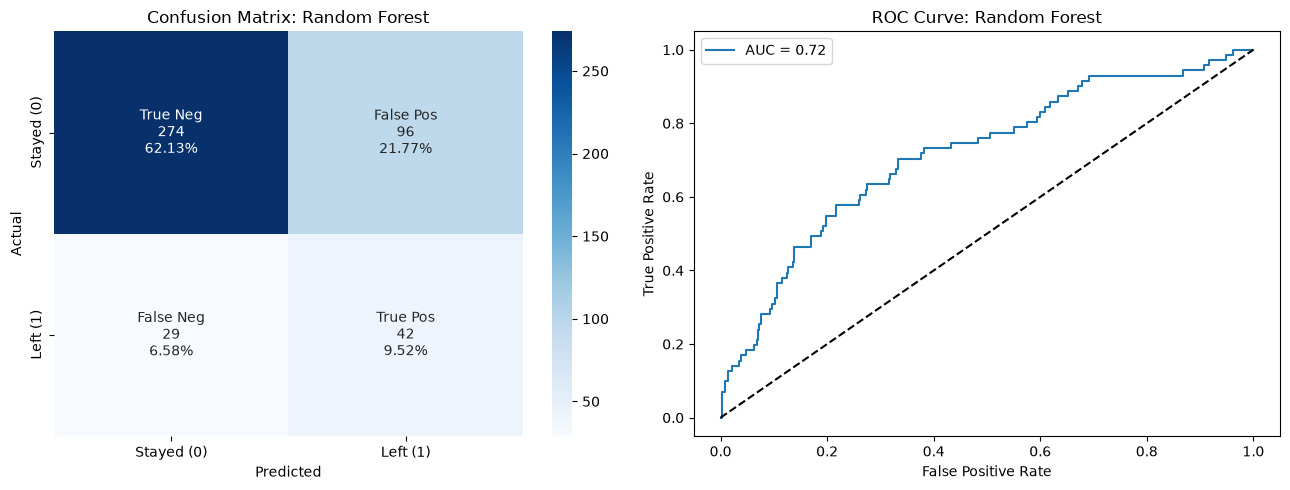

In [399]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                            random_state=42, n_jobs=-1)
rf.fit(X_train_sm, Y_train_sm)
evaluate("Random Forest", rf)

## Logistic Regression

C:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


===== Logistic Regression =====
   Metric  Score
 Accuracy 0.8390
Precision 0.5000
   Recall 0.5352
 F1-Score 0.5170
  ROC-AUC 0.7939


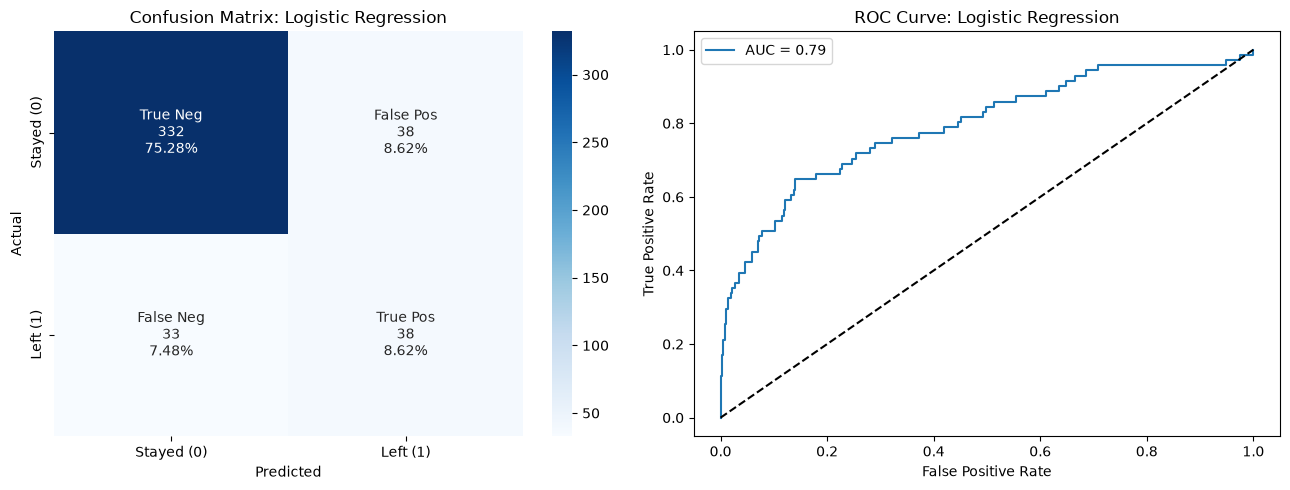


===== Logistic Regression: probability-error metrics =====
MAE       : 0.1979
RMSE      : 0.3214
R-squared : 0.2354


In [400]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr = LogisticRegression(max_iter=2000, random_state=42)
lr.fit(X_train_sm, Y_train_sm)
evaluate("Logistic Regression", lr)

# Supplementary regression-style metrics on predicted probabilities
p = lr.predict_proba(X_test)[:, 1]
print("\n===== Logistic Regression: probability-error metrics =====")
print(f"MAE       : {mean_absolute_error(Y_test, p):.4f}")
print(f"RMSE      : {np.sqrt(mean_squared_error(Y_test, p)):.4f}")
print(f"R-squared : {r2_score(Y_test, p):.4f}")

## Decision Tree Classifier

===== Decision Tree =====
   Metric  Score
 Accuracy 0.6848
Precision 0.2848
   Recall 0.6338
 F1-Score 0.3930
  ROC-AUC 0.6941


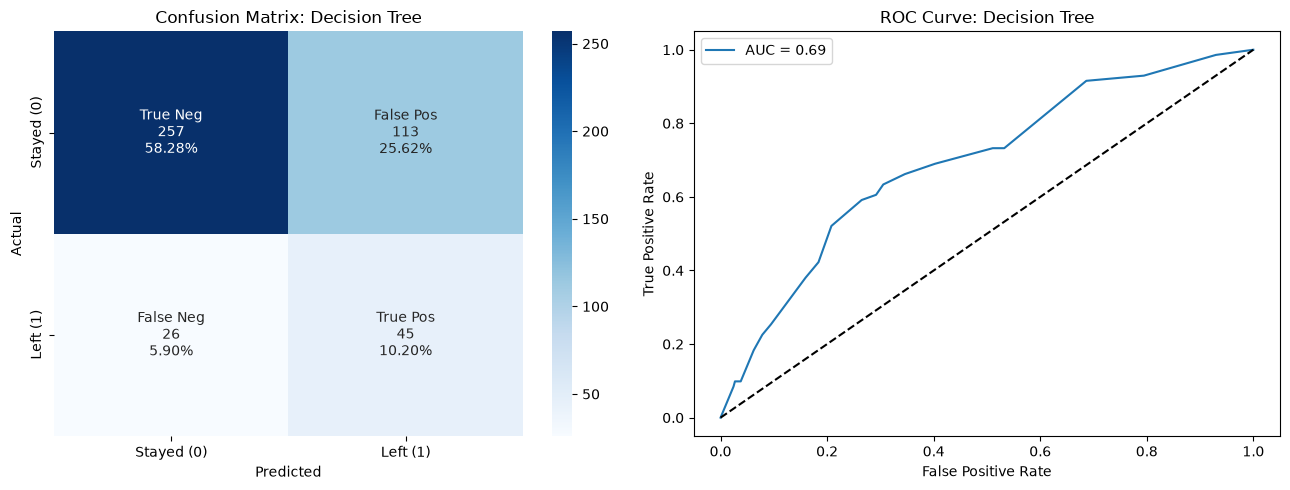

In [401]:
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)
dt.fit(X_train_sm, Y_train_sm)
evaluate("Decision Tree", dt)

,Threshold,Precision,Recall,F1,Caught,Missed,False alarms
Model,,,,,,,
Logistic Regression,0.35,0.500,0.535,0.517,38,33,38
Random Forest,0.35,0.304,0.592,0.402,42,29,96
Decision Tree,0.35,0.285,0.634,0.393,45,26,113


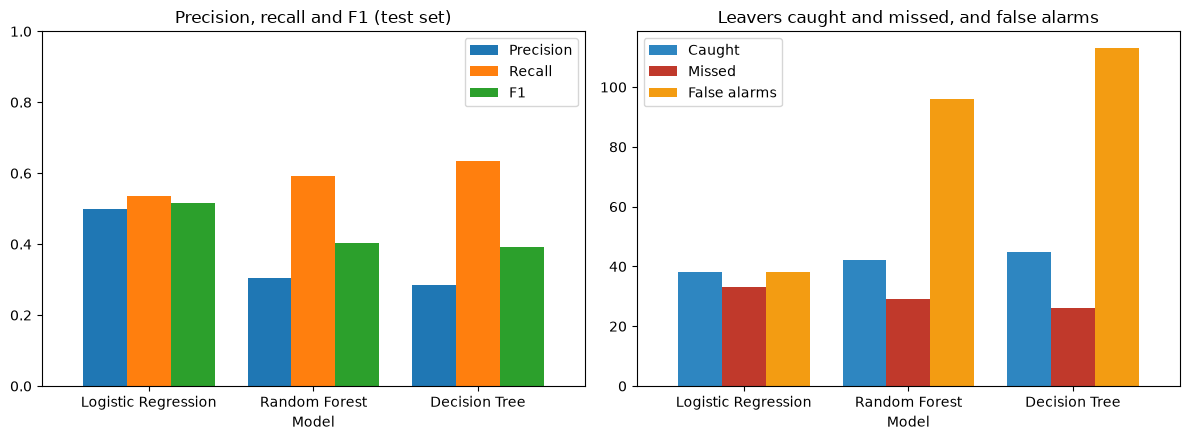

In [402]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

models = {"Logistic Regression": (lr, 0.35), "Random Forest": (rf, 0.35), "Decision Tree": (dt, 0.35)} 

rows = []
for name, (m, t) in models.items():
    pred = (m.predict_proba(X_test)[:, 1] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(Y_test, pred).ravel()
    rows.append({"Model": name, "Threshold": t, "Precision": precision_score(Y_test, pred),
                 "Recall": recall_score(Y_test, pred), "F1": f1_score(Y_test, pred),
                 "Caught": tp, "Missed": fn, "False alarms": fp})
res = pd.DataFrame(rows).set_index("Model").round(3)
display(res)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
res[["Precision", "Recall", "F1"]].plot(kind="bar", ax=ax[0], rot=0, width=0.8)
ax[0].set_ylim(0, 1); ax[0].set_title("Precision, recall and F1 (test set)")
res[["Caught", "Missed", "False alarms"]].plot(kind="bar", ax=ax[1], rot=0, width=0.8,
                                                color=["#2e86c1", "#c0392b", "#f39c12"])
ax[1].set_title("Leavers caught and missed, and false alarms")
plt.tight_layout(); plt.show()